# A Gaussian dust prior next to the scattering loss

[`04_scattering_sampler_pysm_dust.ipynb`](04_scattering_sampler_pysm_dust.ipynb) found that the scattering posterior cannot sample the dust frequency exponent $\beta_d$: the chain runs away to high $\beta_d$ and high $r$. The suspected cause is that the scattering loss constrains 360 numbers of a 32,768-pixel dust field and is not a normalized density of that field.

This notebook tests the proposed fix. `scattering_posterior` and `sample_scattering_posterior` have a flag, `gaussian_dust_prior`, that keeps the Gaussian dust prior of the Gaussian model and multiplies it by the scattering loss:

| Dust term of the log-posterior | `gaussian_dust_prior` | Dust parameters |
|---|---|---|
| $-\dfrac{1}{2\sigma^2}\sum_i \left[\log S_i(g) - \log S_i^{\rm target}\right]^2$ | `False` | none |
| $-\tfrac12\left[g^\dagger C_g^{-1} g + \log\det C_g\right] - \dfrac{1}{2\sigma^2}\sum_i \left[\log S_i(g) - \log S_i^{\rm target}\right]^2$ | `True` | 2 amplitudes, 2 knees |

**The limits of notebook 04 still apply:** the target $S^{\rm target}$ is computed from the true dust field, $\sigma$ is hand-chosen, and there is one map and one chain per configuration.

In [1]:
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.chain_analysis import product_moments, product_pdf
from cmb_scattering.simulate_dust import PYSM_DUST, simulate_data
from cmb_scattering.likelihoods import log_scattering_coefficients
from cmb_scattering.sampler import (DUST_FIELD_NAME, PARAM_BOUNDS, PARAM_ORDER,
                                    sample_gaussian_posterior, sample_scattering_posterior)

#importing cmb_lensing.chain_analysis switches matplotlib to the file-only Agg backend,
#so switch back to drawing figures in the notebook
%matplotlib inline

nside = 128
theta_pix = 20.0
uk_arcmin = 3.0
map_seed = 0
r_true = 0.03
frequency_exponent_true = 1.49

#the PySM d9 data set of notebook 04
sim = simulate_data(nside, theta_pix, map_seed, r_true, frequency_exponent_true,
                    uk_arcmin = uk_arcmin, dust_model = PYSM_DUST)

#the target of the scattering loss: the coefficients of the true dust field
target_log_scattering_coefficients = log_scattering_coefficients(sim["dust_field"])

## The four chains

All four run on the same data, sample $\beta_d$, and use the same sampler seed.

| Chain | Sampler | Gaussian dust prior | Scattering loss |
|---|---|---|---|
| Gaussian | `sample_gaussian_posterior` (exact dust draw) | yes | no |
| scattering only | `sample_scattering_posterior` (HMC dust update) | no | $\sigma = 0.1$ |
| scattering + Gaussian prior | `sample_scattering_posterior`, `gaussian_dust_prior = True` | yes | $\sigma = 0.1$ |
| Gaussian prior, HMC | `sample_scattering_posterior`, `gaussian_dust_prior = True` | yes | switched off ($\sigma = 10^6$) |

The second chain is the runaway of notebook 04. The fourth is a control: it has the same posterior as the first chain but the dust update of the third, so a difference between the third and the fourth is what the scattering loss does, and a difference between the first and the fourth is what the change of dust update does.

In [2]:
num_iterations = 300
chain_seed = 1
#iterations dropped from the start of each chain
burn_in = 50
#width of the L2 loss on each log scattering coefficient
scattering_width = 0.1
#a width so large that the scattering term vanishes
NO_SCATTERING_WIDTH = 1e6

#starting dust parameters, proposal widths and knee bounds as in 04_scattering_sampler_pysm_dust.ipynb
FITTED_DUST_PARAMS = {"dust_amplitude_ee": 28.87, "dust_knee_ee": -0.70,
                      "dust_amplitude_bb": 15.76, "dust_knee_bb": -0.63}
param_init = dict(FITTED_DUST_PARAMS, r = r_true, frequency_exponent = frequency_exponent_true)
proposal_widths = {
    "dust_amplitude_ee": 0.8,
    "dust_amplitude_bb": 0.4,
    "dust_knee_ee": 0.02,
    "dust_knee_bb": 0.02,
    "r": 0.008,
    "frequency_exponent": 0.002,
}
#the scattering-only posterior has no dust parameters
SCATTERING_ONLY_PARAMS = ["r", "frequency_exponent"]
scattering_only_proposal_widths = {name: proposal_widths[name] for name in SCATTERING_ONLY_PARAMS}
WIDE_KNEE_BOUNDS = (-2.0, 0.0)
param_bounds = dict(PARAM_BOUNDS, dust_knee_ee = WIDE_KNEE_BOUNDS, dust_knee_bb = WIDE_KNEE_BOUNDS)

model_arguments = (sim["data"], sim["noise_covariance"], sim["scalar_covariance"],
                   sim["tensor_covariance"], sim["mask"], sim["beam"])

def run_scattering(width, widths, gaussian_dust_prior):
    return sample_scattering_posterior(*model_arguments, param_init,
                                       target_log_scattering_coefficients,
                                       scattering_width = width, proposal_widths = widths,
                                       param_bounds = param_bounds,
                                       gaussian_dust_prior = gaussian_dust_prior,
                                       num_iterations = num_iterations, seed = chain_seed,
                                       frequencies = sim["frequencies"])

GAUSSIAN, SCATTERING_ONLY = "Gaussian", "scattering only"
COMBINED, GAUSSIAN_HMC = "scattering + Gaussian prior", "Gaussian prior, HMC"
chains = {}
#capture the per-iteration acceptance printout
with contextlib.redirect_stdout(io.StringIO()):
    chains[GAUSSIAN] = sample_gaussian_posterior(*model_arguments, param_init,
                                                 proposal_widths = proposal_widths,
                                                 param_bounds = param_bounds,
                                                 num_iterations = num_iterations, seed = chain_seed,
                                                 frequencies = sim["frequencies"])
    chains[SCATTERING_ONLY] = run_scattering(scattering_width, scattering_only_proposal_widths, False)
    chains[COMBINED] = run_scattering(scattering_width, proposal_widths, True)
    chains[GAUSSIAN_HMC] = run_scattering(NO_SCATTERING_WIDTH, proposal_widths, True)
sample_histories = {label: chain[0] for label, chain in chains.items()}
acceptance_rates = {label: chain[1] for label, chain in chains.items()}
logposterior_values = {label: chain[2] for label, chain in chains.items()}

print(f"{'acceptance rate':>20}  " + "  ".join(f"{label:>27}" for label in chains))
for name in PARAM_ORDER + [DUST_FIELD_NAME]:
    rates = [f"{acceptance_rates[label][name]:27.2f}" if name in acceptance_rates[label]
             else f"{'-':>27}" for label in chains]
    print(f"{name:>20}  " + "  ".join(rates))

     acceptance rate                     Gaussian              scattering only  scattering + Gaussian prior          Gaussian prior, HMC
   dust_amplitude_ee                         0.53                            -                         0.49                         0.47
   dust_amplitude_bb                         0.48                            -                         0.54                         0.55
        dust_knee_ee                         0.41                            -                         0.43                         0.41
        dust_knee_bb                         0.43                            -                         0.38                         0.41
                   r                         0.45                         0.48                         0.47                         0.48
  frequency_exponent                         0.37                         0.52                         0.33                         0.33
          dust_field                     

A dash marks a parameter the chain does not sample. The dust field's rate is the acceptance rate of its HMC update, which the Gaussian prior leaves near 60 %. Its precision is added to the HMC mass matrix.

## Does the Gaussian prior stop the runaway?

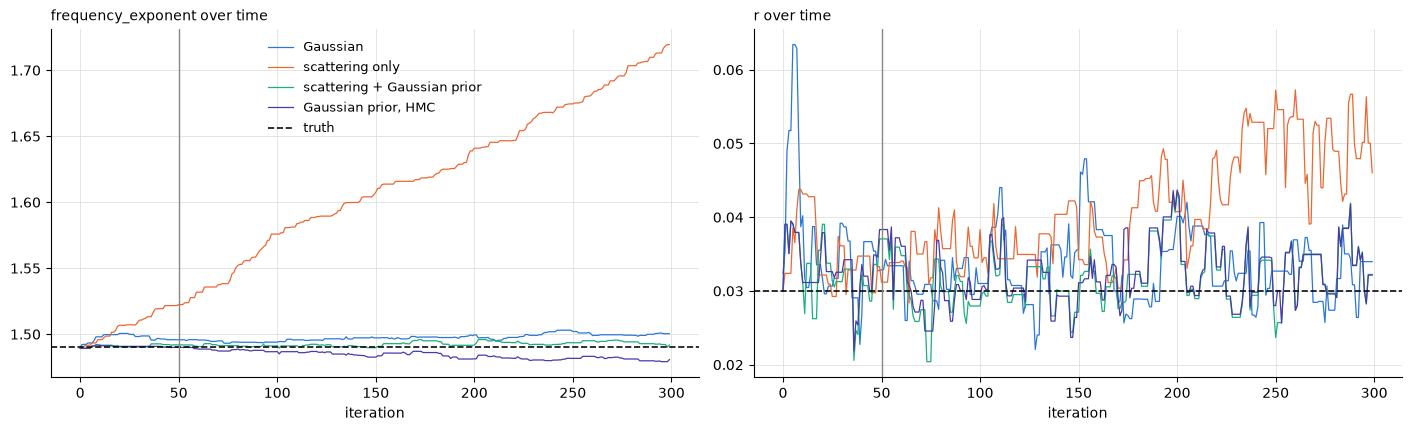

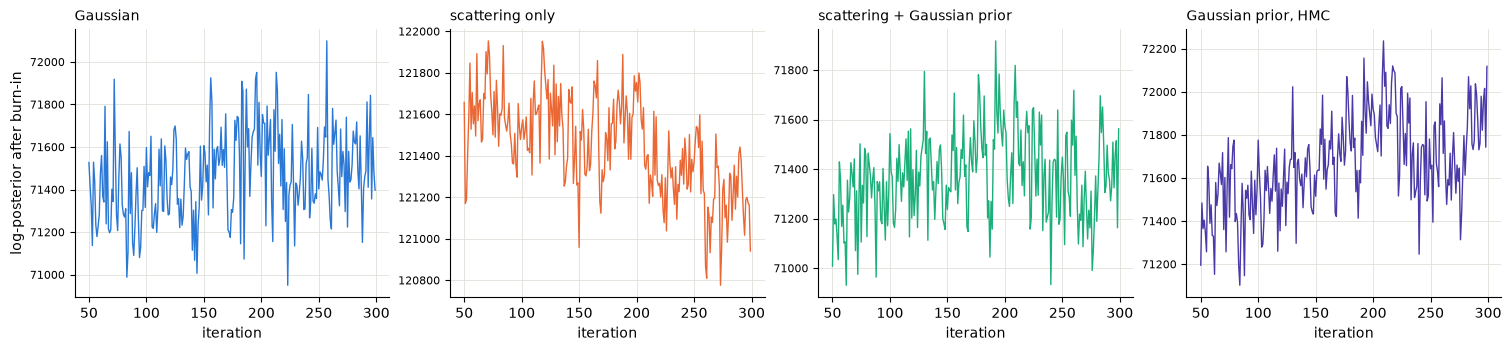

                      chain  beta, first  beta, last   r, first    r, last  logpost, first  logpost, last
                   Gaussian        1.495       1.500     0.0316     0.0317           71393          71515
            scattering only        1.532       1.708     0.0340     0.0498          121629         121202
scattering + Gaussian prior        1.492       1.493     0.0310     0.0336           71231          71373
        Gaussian prior, HMC        1.489       1.480     0.0323     0.0335           71468          71812


In [3]:
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
colors = {GAUSSIAN: "#2a78d6", SCATTERING_ONLY: "#eb6834", COMBINED: "#1baf7a", GAUSSIAN_HMC: "#4a3aa7"}
truths = {"r": r_true, "frequency_exponent": frequency_exponent_true}

def style_axis(ax):
    ax.grid(color = GRID, lw = 0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize = (14, 4.2), constrained_layout = True)
for ax, name in zip(axes, ("frequency_exponent", "r")):
    for label in chains:
        ax.plot(sample_histories[label][name], color = colors[label], lw = 0.9, label = label)
    ax.axhline(truths[name], color = INK, lw = 1.2, ls = "--", label = "truth")
    ax.axvline(burn_in, color = MUTED, lw = 1)
    ax.set_title(f"{name} over time", loc = "left", fontsize = 10)
    ax.set_xlabel("iteration")
    style_axis(ax)
axes[0].legend(frameon = False, fontsize = 9)
plt.show()

fig, axes = plt.subplots(1, len(chains), figsize = (15, 3.4), constrained_layout = True)
for ax, label in zip(axes, chains):
    #the first iterations are far below the rest and are left out so the later shape shows
    iterations = np.arange(burn_in, num_iterations)
    ax.plot(iterations, logposterior_values[label][burn_in:], color = colors[label], lw = 1.0)
    ax.set_title(label, loc = "left", fontsize = 10)
    ax.set_xlabel("iteration")
    ax.ticklabel_format(axis = "y", useOffset = False, style = "plain")
    ax.tick_params(axis = "y", labelsize = 8)
    style_axis(ax)
axes[0].set_ylabel("log-posterior after burn-in")
plt.show()

#the last tenth of each chain against its first tenth after burn-in
tail = (num_iterations - burn_in) // 10
print(f"{'chain':>27}  {'beta, first':>11}  {'beta, last':>10}  {'r, first':>9}  {'r, last':>9}  "
      f"{'logpost, first':>14}  {'logpost, last':>13}")
for label in chains:
    beta = sample_histories[label]["frequency_exponent"][burn_in:]
    r = sample_histories[label]["r"][burn_in:]
    logposterior = logposterior_values[label][burn_in:]
    print(f"{label:>27}  {beta[:tail].mean():11.3f}  {beta[-tail:].mean():10.3f}  {r[:tail].mean():9.4f}  "
          f"{r[-tail:].mean():9.4f}  {logposterior[:tail].mean():14.0f}  {logposterior[-tail:].mean():13.0f}")

**Yes, over these 300 iterations.**

- **Scattering only:** $\beta_d$ climbs almost linearly from 1.49 to 1.72 and takes $r$ with it, to about 0.05. Its log-posterior falls by about 430 between the first and the last 25 iterations after burn-in. This is the runaway of notebook 04.
- **Scattering + Gaussian prior:** $\beta_d$ stays within 0.005 of the truth and ends at 1.493. $r$ stays near 0.03.
- **The two Gaussian-model chains** stay within 0.011 of the truth: the Gaussian sampler ends at 1.500 and its HMC version at 1.480.

**What 300 iterations cannot show:**

- **A posterior of $\beta_d$.** In the Gaussian model $\beta_d$ decorrelates over about 250 iterations (measured on a 6000-iteration chain, see `PROJECT_SUMMARY.md`), so each chain here holds about one independent sample of it. The spread between the three chains (1.480 to 1.500) is the only indication of its width.
- **Whether the HMC control's slow decline is a drift.** It loses 0.010 in 300 iterations, more than 20 times slower than the runaway and in the opposite direction. Slow mixing would look the same; a longer chain would tell.
- **Convergence of the dust parameters.** The log-posteriors of the three chains with a Gaussian prior are still rising at the end, as the dust knees move from their starting values of $-0.70$ and $-0.63$ toward about $-1.0$.

## The recovered r

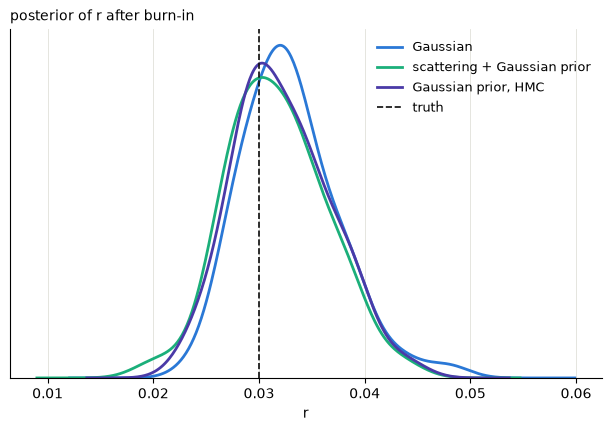

                      chain    mean r       std      bias   z-score     IAT  thinned samples
                   Gaussian    0.0329    0.0049   +0.0029     +0.60     4.4               63
scattering + Gaussian prior    0.0317    0.0050   +0.0017     +0.33     6.8               42
        Gaussian prior, HMC    0.0322    0.0048   +0.0022     +0.45     6.6               42

scattering + Gaussian prior  minus  Gaussian prior, HMC: -0.0005 (-0.11 of the latter's std), width ratio 1.04
scattering + Gaussian prior  minus  Gaussian: -0.0013 (-0.26 of the latter's std), width ratio 1.02
Gaussian prior, HMC  minus  Gaussian: -0.0008 (-0.15 of the latter's std), width ratio 0.99

scattering + Gaussian prior and Gaussian prior, HMC, sample by sample: rms difference in r 0.0016, correlation 0.93

mean of the last 25 iterations:
                      chain   dust_amplitude_ee   dust_amplitude_bb        dust_knee_ee        dust_knee_bb                   r  frequency_exponent
                   Gaussia

In [4]:
KDE_GRID_POINTS = 400
#how far past the samples' range the density is drawn, as a fraction of that range
KDE_GRID_PADDING = 0.5
#the chains that keep the Gaussian prior; the scattering-only chain is not stationary\n#and has no posterior to summarize
STATIONARY_CHAINS = [GAUSSIAN, COMBINED, GAUSSIAN_HMC]

def chain_summary(chain, truth):
    #IAT, thinned samples, and the KDE's grid, density, mean and std for one parameter chain
    iat = integrated_autocorrelation_time(autocorrelation(chain))
    samples = chain[::max(int(iat), 1)]
    low, high = samples.min(), samples.max()
    low, high = min(low, truth), max(high, truth)
    padding = KDE_GRID_PADDING * (high - low)
    grid = np.linspace(low - padding, high + padding, KDE_GRID_POINTS)
    density = product_pdf([gaussian_kde(samples)(grid)], grid)
    mean, std = product_moments(density, grid)
    return {"iat": iat, "num_samples": len(samples), "grid": grid, "density": density,
            "mean": mean, "std": std}

r_summary = {label: chain_summary(sample_histories[label]["r"][burn_in:], r_true)
             for label in STATIONARY_CHAINS}

fig, ax = plt.subplots(figsize = (6, 4.2), constrained_layout = True)
for label in STATIONARY_CHAINS:
    ax.plot(r_summary[label]["grid"], r_summary[label]["density"], color = colors[label], lw = 2, label = label)
ax.axvline(r_true, color = INK, lw = 1.2, ls = "--", label = "truth")
ax.set_xlabel("r")
ax.set_yticks([])
ax.set_ylim(bottom = 0)
ax.set_title("posterior of r after burn-in", loc = "left", fontsize = 10)
ax.legend(frameon = False, fontsize = 9)
style_axis(ax)
plt.show()

print(f"{'chain':>27}  {'mean r':>8}  {'std':>8}  {'bias':>8}  {'z-score':>8}  {'IAT':>6}  {'thinned samples':>15}")
for label in STATIONARY_CHAINS:
    summary = r_summary[label]
    bias = summary["mean"] - r_true
    print(f"{label:>27}  {summary['mean']:8.4f}  {summary['std']:8.4f}  {bias:+8.4f}  "
          f"{bias / summary['std']:+8.2f}  {summary['iat']:6.1f}  {summary['num_samples']:15d}")

def print_shift(label_a, label_b):
    shift = r_summary[label_a]["mean"] - r_summary[label_b]["mean"]
    print(f"{label_a}  minus  {label_b}: {shift:+.4f} "
          f"({shift / r_summary[label_b]['std']:+.2f} of the latter's std), "
          f"width ratio {r_summary[label_a]['std'] / r_summary[label_b]['std']:.2f}")

print()
print_shift(COMBINED, GAUSSIAN_HMC)
print_shift(COMBINED, GAUSSIAN)
print_shift(GAUSSIAN_HMC, GAUSSIAN)

#the two HMC chains share their seed, so they can be compared sample by sample
r_combined = sample_histories[COMBINED]["r"][burn_in:]
r_gaussian_hmc = sample_histories[GAUSSIAN_HMC]["r"][burn_in:]
print(f"\nscattering + Gaussian prior and Gaussian prior, HMC, sample by sample: rms difference in r "
      f"{np.sqrt(np.mean((r_combined - r_gaussian_hmc)**2)):.4f}, correlation "
      f"{np.corrcoef(r_combined, r_gaussian_hmc)[0, 1]:.2f}")

#where the dust parameters of the chains with a Gaussian prior are at the end (not converged)
print(f"\nmean of the last {tail} iterations:")
print(f"{'chain':>27}  " + "  ".join(f"{name:>18}" for name in PARAM_ORDER))
for label in STATIONARY_CHAINS:
    print(f"{label:>27}  " + "  ".join(f"{sample_histories[label][name][-tail:].mean():18.4f}"
                                        for name in PARAM_ORDER))

$r$ decorrelates in about 5 iterations, so it is the one parameter these short chains can summarize. Each density is drawn from 42 to 63 thinned samples.

- **All three chains agree:** $0.0329 \pm 0.0049$ (Gaussian), $0.0317 \pm 0.0050$ (scattering + Gaussian prior), $0.0322 \pm 0.0048$ (Gaussian prior, HMC), against a truth of 0.03. Every chain is within 0.6 standard deviations of the truth and within 0.26 of the others.
- **The scattering loss again does almost nothing to $r$.** The chain with it and the control without it share a seed and track each other sample by sample: correlation 0.93, mean shift $-0.0005$. Notebook 04 found the same without the Gaussian prior (0.92).
- **The HMC dust update reproduces the Gaussian sampler** to within 0.15 standard deviations in $r$, which is inside the noise of about 50 samples.

The last table shows where the dust parameters are at the end of each chain. They have not converged, and PySM dust has no true value for them.

## What this shows

1. **Keeping the Gaussian dust prior stops the $\beta_d$ runaway** in a 300-iteration chain: $\beta_d$ stays within 0.005 of the truth where the scattering-only chain gains 0.23. This supports the explanation of notebook 04, that the scattering loss alone is not a normalized density of the dust field.
2. **$r$ does not change.** With or without the scattering loss next to the Gaussian prior, $r$ is the same to within 0.11 standard deviations, and all chains are within 0.6 standard deviations of the truth.
3. **So the scattering loss is now usable but not yet useful on this data.** The data measure the dust well enough at 3 $\mu K$-arcmin in three channels that the dust model has little effect on $r$.

**What this does not show:**

- The long-run posterior of $\beta_d$ and of the dust parameters with the combined dust term. That needs chains of several thousand iterations.
- Any change of bias in $r$. One map and about 50 independent samples per chain cannot resolve a shift below about 0.15 standard deviations.
- That the combined dust term is correctly normalized in the dust parameters. The integral of (Gaussian prior $\times$ scattering loss) over the dust field depends on the amplitudes and knees and is not divided out, so the loss acts as an extra, implicit prior on them.

The target is still the true dust field's coefficients and $\sigma$ is still hand-chosen.